Necessary Packages and Libraries

In [37]:
# Deep learning framework
!pip install -q torch torchvision

# YOLO object detection
!pip install -q ultralytics

# Object tracking, line counting, and heatmap visualization
!pip install -q supervision

# Video processing
!pip install -q opencv-python-headless

# Numerical operations and visualization
!pip install -q numpy matplotlib pillow

In [38]:
# General utilities
import os
import numpy as np

# Deep learning
import torch
import torchvision

# YOLO
from ultralytics import YOLO

# Object tracking and visualization
import supervision as sv

# Video processing
import cv2

# Plotting and image display
import matplotlib.pyplot as plt
from PIL import Image

# Display video and images in Google Colab
from IPython.display import display, Video, Image as IPythonImage

# Download files
import requests
from io import BytesIO

print("All required libraries imported successfully.")
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)
print("Supervision version:", sv.__version__)

All required libraries imported successfully.
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
OpenCV version: 5.0.0
Supervision version: 0.31.3


Downloading Video

In [39]:
VIDEO_URL = (
    "https://media.roboflow.com/"
    "supervision/video-examples/people-walking.mp4"
)

VIDEO_PATH = "/content/people-walking.mp4"


print("Video downloaded:", os.path.getsize(VIDEO_PATH), "bytes")

Video downloaded: 7606633 bytes


Seeing the characteristics of the video

Width: 1920
Height: 1080
FPS: 25.0
Total frames: 341


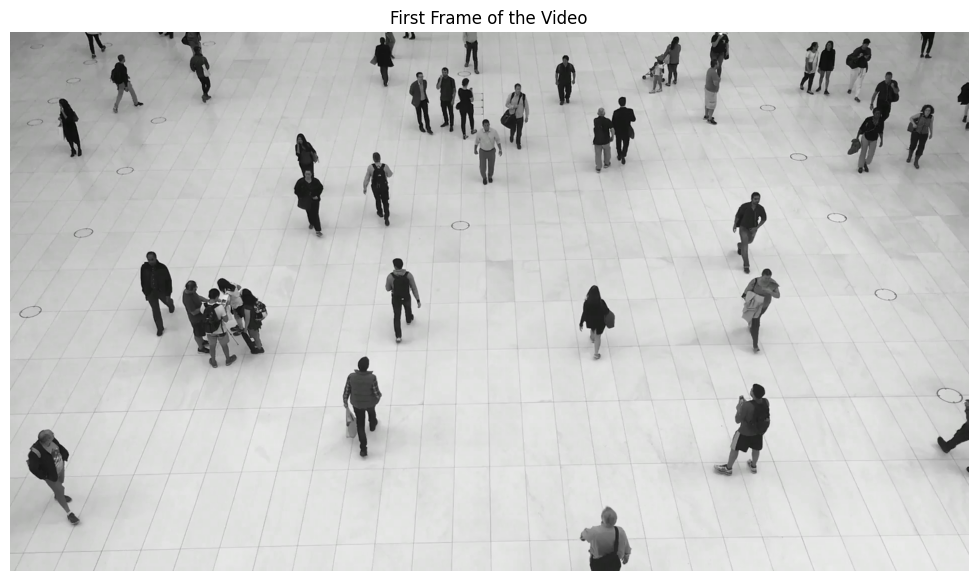

In [40]:
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError("Could not open the input video.")

WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
FPS = cap.get(cv2.CAP_PROP_FPS)
TOTAL_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("Width:", WIDTH)
print("Height:", HEIGHT)
print("FPS:", FPS)
print("Total frames:", TOTAL_FRAMES)

ret, frame = cap.read()
cap.release()

if ret:
    plt.figure(figsize=(14, 7))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("First Frame of the Video")
    plt.axis("off")
    plt.show()

Loading Yolo

In [41]:
# Load a pretrained YOLO11 nano model
model = YOLO("yolo11n.pt")

Installing ByTrack

In [42]:
!pip install -q trackers

from trackers import ByteTrackTracker

tracker = ByteTrackTracker(
    track_activation_threshold=0.25,
    minimum_consecutive_frames=1
)

print("ByteTrack initialized successfully.")

ByteTrack initialized successfully.


Two Horizontal Lines

From Roboflow PolygonZone the coordinates are obtained.


In [43]:
# Initial line positions
UPPER_LINE_Y = int(HEIGHT * 0.35)
LOWER_LINE_Y = int(HEIGHT * 0.70)

print("Upper line Y-coordinate:", UPPER_LINE_Y)
print("Lower line Y-coordinate:", LOWER_LINE_Y)

assert 0 < UPPER_LINE_Y < LOWER_LINE_Y < HEIGHT

Upper line Y-coordinate: 378
Lower line Y-coordinate: 756


In [44]:
upper_line_start = sv.Point(0, UPPER_LINE_Y)
upper_line_end = sv.Point(WIDTH - 1, UPPER_LINE_Y)

lower_line_start = sv.Point(0, LOWER_LINE_Y)
lower_line_end = sv.Point(WIDTH - 1, LOWER_LINE_Y)

Initialize counter and heatmap

In [45]:
# Store the previous center position of each tracking ID
previous_positions = {}

# Prevent repeated counts for the same ID in each direction
counted_in_ids = set()
counted_out_ids = set()

# Initialize counters
in_count = 0
out_count = 0

# Accumulate people locations for the heatmap
heatmap_accumulator = np.zeros(
    (HEIGHT, WIDTH),
    dtype=np.float32
)

print("Counters and heatmap initialized.")

Counters and heatmap initialized.


New video by counting people

In [46]:
# Output video path
OUTPUT_VIDEO = "/content/people_flow_output.mp4"

# Open the input video
cap = cv2.VideoCapture(VIDEO_PATH)

# Create the output video writer
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    OUTPUT_VIDEO,
    fourcc,
    FPS if FPS > 0 else 25.0,
    (WIDTH, HEIGHT)
)

if not cap.isOpened():
    raise RuntimeError("Could not reopen the input video.")

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create the output video.")

# Annotators for bounding boxes and tracking labels
box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

frame_number = 0

while True:

    # Read the next frame
    ret, frame = cap.read()

    if not ret:
        break

    frame_number += 1

    # ------------------------------------------
    # A. DETECT PEOPLE USING YOLO
    # ------------------------------------------

    result = model.predict(
        frame,
        classes=[0],
        conf=0.25,
        verbose=False
    )[0]

    # Convert YOLO results into Supervision detections
    detections = sv.Detections.from_ultralytics(result)

    # ------------------------------------------
    # B. TRACK PEOPLE USING BYTETRACK
    # ------------------------------------------
    detections = tracker.update(detections)


    # Prepare a copy of the frame for annotations
    annotated_frame = frame.copy()

    # ------------------------------------------
    # C. DRAW BOUNDING BOXES AND TRACKING IDS
    # ------------------------------------------

    annotated_frame = box_annotator.annotate(
        scene=annotated_frame,
        detections=detections
    )

    # ------------------------------------------
    # D. COUNT DIRECTIONAL LINE CROSSINGS
    # ------------------------------------------

    if detections.tracker_id is not None:

        labels = []

        for xyxy, tracker_id in zip(
            detections.xyxy,
            detections.tracker_id
        ):

            if tracker_id is None:
                labels.append("Person")
                continue

            tracker_id = int(tracker_id)

            x1, y1, x2, y2 = xyxy.astype(int)

            # Calculate bounding-box center
            center_x = int((x1 + x2) / 2)
            center_y = int((y1 + y2) / 2)

            # Check whether this ID has a previous position
            if tracker_id in previous_positions:

                previous_x, previous_y = (
                    previous_positions[tracker_id]
                )

                # IN: moving downward across the upper line
                if (
                    previous_y < UPPER_LINE_Y
                    and center_y >= UPPER_LINE_Y
                    and tracker_id not in counted_in_ids
                ):

                    in_count += 1
                    counted_in_ids.add(tracker_id)

                    print(
                        f"IN detected: ID {tracker_id}, "
                        f"frame {frame_number}"
                    )

                # OUT: moving upward across the lower line
                if (
                    previous_y > LOWER_LINE_Y
                    and center_y <= LOWER_LINE_Y
                    and tracker_id not in counted_out_ids
                ):

                    out_count += 1
                    counted_out_ids.add(tracker_id)

                    print(
                        f"OUT detected: ID {tracker_id}, "
                        f"frame {frame_number}"
                    )

            # Update the previous position
            previous_positions[tracker_id] = (
                center_x,
                center_y
            )

            # --------------------------------------
            # E. ACCUMULATE HEATMAP VALUES
            # --------------------------------------

            if (
                0 <= center_x < WIDTH
                and 0 <= center_y < HEIGHT
            ):

                cv2.circle(
                    heatmap_accumulator,
                    (center_x, center_y),
                    15,
                    1.0,
                    thickness=-1
                )

            labels.append(f"ID {tracker_id}")

        # Draw labels beside the bounding boxes
        annotated_frame = label_annotator.annotate(
            scene=annotated_frame,
            detections=detections,
            labels=labels
        )

    # ------------------------------------------
    # F. DRAW THE TWO COUNTING LINES
    # ------------------------------------------

    # Upper line: green
    cv2.line(
        annotated_frame,
        (0, UPPER_LINE_Y),
        (WIDTH - 1, UPPER_LINE_Y),
        (0, 255, 0),
        3
    )

    # Lower line: red
    cv2.line(
        annotated_frame,
        (0, LOWER_LINE_Y),
        (WIDTH - 1, LOWER_LINE_Y),
        (0, 0, 255),
        3
    )

    # ------------------------------------------
    # G. DISPLAY THE COUNTERS
    # ------------------------------------------

    cv2.rectangle(
        annotated_frame,
        (10, 10),
        (270, 105),
        (0, 0, 0),
        thickness=-1
    )

    cv2.putText(
        annotated_frame,
        f"IN: {in_count}",
        (25, 48),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.9,
        (0, 255, 0),
        2
    )

    cv2.putText(
        annotated_frame,
        f"OUT: {out_count}",
        (25, 88),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.9,
        (0, 0, 255),
        2
    )

    # ------------------------------------------
    # H. SAVE THE ANNOTATED FRAME
    # ------------------------------------------

    writer.write(annotated_frame)

    if frame_number % 100 == 0:
        print(
            f"Processed {frame_number}/{TOTAL_FRAMES} frames"
        )

# Release video resources
cap.release()
writer.release()

print("\nVideo processing completed.")
print("Total frames processed:", frame_number)
print("Total IN:", in_count)
print("Total OUT:", out_count)
print("Output video:", OUTPUT_VIDEO)

IN detected: ID -1, frame 1
OUT detected: ID -1, frame 1
OUT detected: ID 0, frame 58
IN detected: ID 9, frame 73
Processed 100/341 frames
OUT detected: ID 11, frame 108
OUT detected: ID 12, frame 124
OUT detected: ID 13, frame 143
IN detected: ID 6, frame 155
Processed 200/341 frames
IN detected: ID 18, frame 230
OUT detected: ID 21, frame 258
Processed 300/341 frames
OUT detected: ID 23, frame 317
OUT detected: ID 25, frame 321

Video processing completed.
Total frames processed: 341
Total IN: 4
Total OUT: 8
Output video: /content/people_flow_output.mp4


Heatmap

In [47]:
# Apply Gaussian smoothing
heatmap_blurred = cv2.GaussianBlur(
    heatmap_accumulator,
    (0, 0),
    sigmaX=25,
    sigmaY=25
)

# Normalize values to the range 0–255
heatmap_normalized = cv2.normalize(
    heatmap_blurred,
    None,
    alpha=0,
    beta=255,
    norm_type=cv2.NORM_MINMAX
).astype(np.uint8)

# Apply a color map
heatmap_color = cv2.applyColorMap(
    heatmap_normalized,
    cv2.COLORMAP_JET
)

# Save the heatmap
OUTPUT_HEATMAP = "/content/final_heatmap.png"

cv2.imwrite(
    OUTPUT_HEATMAP,
    heatmap_color
)

print("Heatmap saved:", OUTPUT_HEATMAP)

Heatmap saved: /content/final_heatmap.png


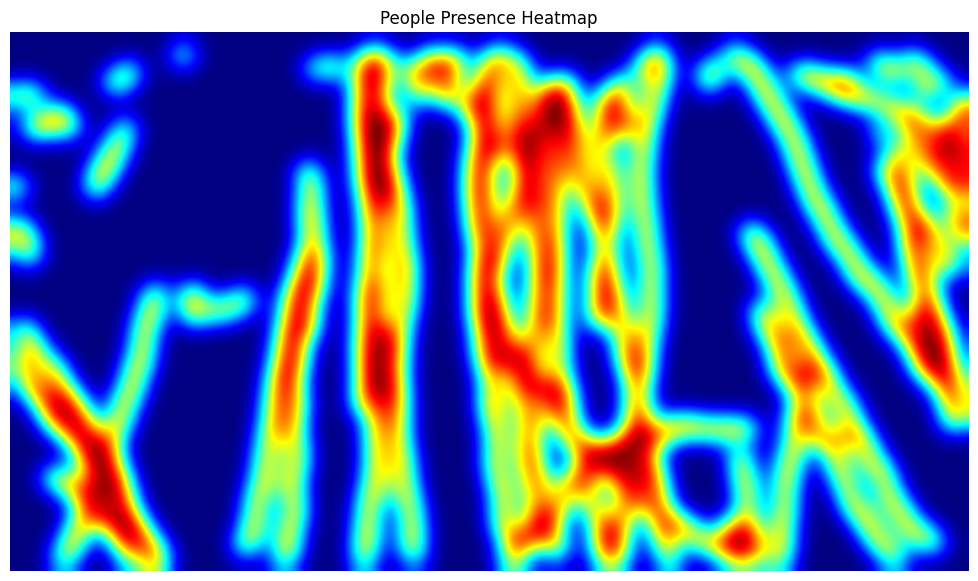

In [48]:
plt.figure(figsize=(14, 7))

plt.imshow(
    cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
)

plt.title("People Presence Heatmap")
plt.axis("off")
plt.show()

Final heatmap as an overlay

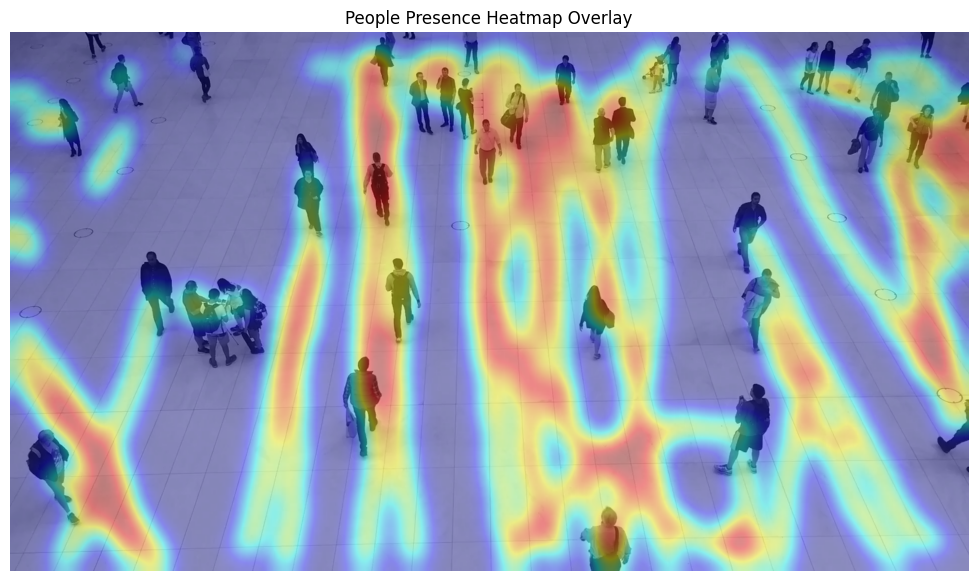

In [49]:
# Read the first frame
cap = cv2.VideoCapture(VIDEO_PATH)

ret, background_frame = cap.read()

cap.release()

if not ret:
    raise RuntimeError("Could not read the first video frame.")

# Blend the original frame and heatmap
heatmap_overlay = cv2.addWeighted(
    background_frame,
    0.6,
    heatmap_color,
    0.4,
    0
)

OUTPUT_OVERLAY = "/content/heatmap_overlay.png"

cv2.imwrite(
    OUTPUT_OVERLAY,
    heatmap_overlay
)

# Display the overlay
plt.figure(figsize=(14, 7))

plt.imshow(
    cv2.cvtColor(heatmap_overlay, cv2.COLOR_BGR2RGB)
)

plt.title("People Presence Heatmap Overlay")
plt.axis("off")
plt.show()

Saving files

In [50]:
from google.colab import files

files.download("/content/people_flow_output.mp4")
files.download("/content/final_heatmap.png")
files.download("/content/heatmap_overlay.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>